Feature Selection is one of the core concepts in machine learning which hugely impacts the performance of your model. The data features that you use to train your machine learning models have a huge influence on the performance you can achieve.

Irrelevant or partially relevant features can negatively impact model performance.

Benefits of performing feature selection:
Reduces Overfitting: Less redundant data means less opportunity to make decisions based on noise(irrelevant data).
Improves Performance: Less misleading data means model's performance improves.
Reduces Training Time: Less data means that algorithms train faster.
Out of the numerous feature selection techniques, we'll be discussing 4 here.

Recursive Feature Elimination (RFE)
Feature Importance using Random Forest
Boruta
XGBoost
All the techniques will be implemented independent of each other and not in succession.

About Dataset
Context

This dataset is originally from the National Institute of Diabetes and Digestive and Kidney Diseases. The objective of the dataset is to diagnostically predict whether or not a patient has diabetes, based on certain diagnostic measurements included in the dataset. Several constraints were placed on the selection of these instances from a larger database. In particular, all patients here are females at least 21 years old of Pima Indian heritage.

Content

The datasets consists of several medical predictor variables and one target variable, class (whether patient have diabetes or not). Predictor variables includes the number of pregnancies the patient has had, their BMI, insulin level, age, and so on.

**Data Description**

1.  preg: Number of times the patient had been pregnant
2.  glucose: Plasma glucose concentration a 2 hours in an oral glucose tolerance test
3.  bp: Diastolic blood pressure (mm Hg)
4.  skin: Triceps skin fold thickness (mm)
5.  insulin: 2-Hour serum insulin (mu U/ml)
6.  bmi: Body mass index (weight in kg/(height in m)^2)
7.  pedi: Diabetes pedigree function
8.  age: Age of the patient in years
9.  class: Have diabetes or not (0 means have no diabetes; 1 means have diabetes); 268 of 768 are 1, the others are 0

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

Importing Data

In [4]:
col_names = ['preg', 'glucose', 'bp', 'skin', 'insulin', 'bmi', 'pedi', 'age', 'class']
data = pd.read_csv("https://raw.githubusercontent.com/dphi-official/Datasets/master/pima-indians-diabetes.csv", names=col_names)
data.head()

,preg,glucose,bp,skin,insulin,bmi,pedi,age,class
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   preg     768 non-null    int64  
 1   glucose  768 non-null    int64  
 2   bp       768 non-null    int64  
 3   skin     768 non-null    int64  
 4   insulin  768 non-null    int64  
 5   bmi      768 non-null    float64
 6   pedi     768 non-null    float64
 7   age      768 non-null    int64  
 8   class    768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [ ]:
data.dtypes

,0
preg,int64
glucose,int64
bp,int64
skin,int64
insulin,int64
bmi,float64
pedi,float64
age,int64
class,int64


Check for missing values

In [ ]:
data.isnull().sum()

,0
preg,0
glucose,0
bp,0
skin,0
insulin,0
bmi,0
pedi,0
age,0
class,0


There are no missing values

Correlation matrix

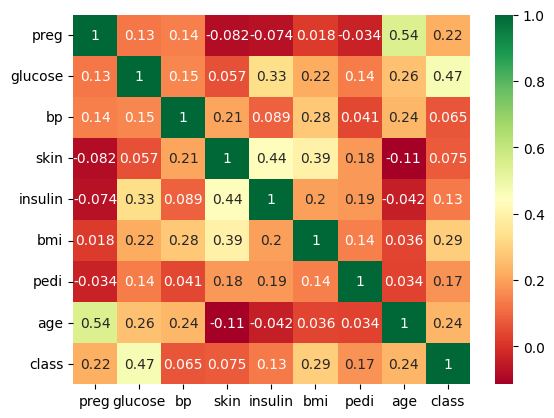

<Figure size 1500x1200 with 0 Axes>

In [6]:
sns.heatmap(data.corr(),annot=True,cmap="RdYlGn")
plt.figure(figsize=(15,12))
plt.show()

In [ ]:
np.min(data.corr())

-0.11397026236774152

You may want to remove irrelevant features by intution or just looking at the heat map. In general it is not advisable to be influenced by one's bias or intution

In [7]:
# selecting the input and the output variables
x = data.drop('class',axis = 1)
y = data['class']

In [8]:
print(x.shape)
print(y.shape)

(768, 8)
(768,)


In [10]:
#splitting our data into test and train tests
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.33, random_state=1)

Basic Steps
The steps that we'll follow will look like:

1.  Train a baseline classifier ( any classifier like logistic regression or random forest trained with all the features in dataset)
2.  Identify the most important features using a feature selection technique
3.  rcreate a new ‘limited features’ dataset containing only those features
4.  Train a second classifier on this new dataset
5.  Compare the accuracy of the ‘full featured’(baseline) classifier to the accuracy of the ‘limited featured’(new) classifier

1. Recursive Feature Elimination (RFE)
Recursive = Something that happens repeatedly

As the name suggests, Recursive Feature Elimination works by recursively(repeatedly) removing features and building a model on the features that remain.

The example below uses RFE with the logistic regression algorithm to select the top 3 features. The choice of algorithm does not matter, instead of logistic we can use any other algorithm that is skillful and consistent.

We use feature selection module from sklearn library to apply Recursive Feature Elimination (RFE)

Building our baseline model using Logistic Regression

In [11]:
from sklearn.linear_model import LogisticRegression
clf_lr = LogisticRegression()
clf_lr.fit(X_train,y_train)

/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression()

In [12]:
from sklearn.metrics import confusion_matrix,accuracy_score
y_pred = clf_lr.predict(X_test)
print(confusion_matrix(y_test,y_pred))
print(accuracy_score(y_test,y_pred))

[[147  15]
 [ 41  51]]
0.7795275590551181


In [13]:
print("The accuracy score for our logistic model is ",accuracy_score(y_test,y_pred)*100)

The accuracy score for our logistic model is  77.95275590551181


Appling Recursive Feature Elimination

In [14]:
from sklearn.feature_selection import RFE
rfe = RFE(estimator = clf_lr,step=1)
rfe.fit(X_train,y_train)
print("Num Features: %d" % rfe.n_features_)
print("Selected Features: %s" % rfe.support_)
print("Feature Ranking: %s" % rfe.ranking_)

Num Features: 4
Selected Features: [ True  True False False False  True  True False]
Feature Ranking: [1 1 3 4 5 1 1 2]


/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


# **Representing feature ranks in the form of a table**

Through the output mentioned above we can't understand which feature has a better rank unless we see the index of each. In order to better visualise, we can put it in the form of a table with ranking as mentioned below.

In [ ]:
selected_rfe_features = pd.DataFrame({'Features':list(X_train.columns),'Ranking':rfe.ranking_})
selected_rfe_features.sort_values(by='Ranking')

,Features,Ranking
0,preg,1
1,glucose,1
5,bmi,1
6,pedi,1
7,age,2
2,bp,3
3,skin,4
4,insulin,5


The feature names preg,glucose,bmi,pedi are the most important features in our model

Creating a new Subset of the data with only the selected features

In [15]:
X_train_rfe = rfe.transform(X_train)
X_test_rfe = rfe.transform(X_test)
# fitting our baseline model using the transformed data
clf_lr.fit(X_train_rfe,y_train)

LogisticRegression()

In [ ]:
#checking performance
y_pred_rfe = clf_lr.predict(X_test_rfe)
print(confusion_matrix(y_test,y_pred_rfe))
print(accuracy_score(y_test,y_pred_rfe))

[[148  14]
 [ 42  50]]
0.7795275590551181


Our model has not yet improved so we can try another elimination method. But as you can see this will reduce the training time of our model hence model performance will definately improve.

Feature Importance Using Random Forest

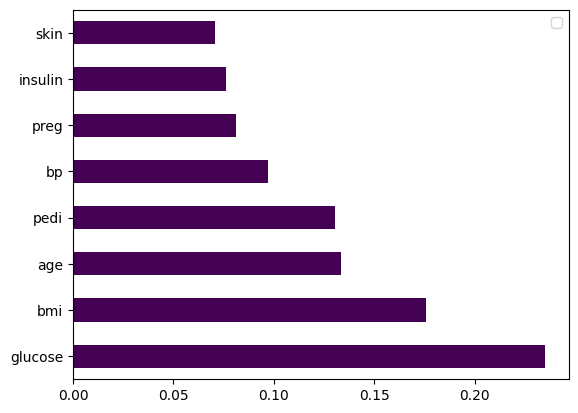

In [ ]:
from sklearn.ensemble import RandomForestClassifier
rf_clf = RandomForestClassifier(n_estimators = 1000,random_state=1,n_jobs=-1)
rf_clf.fit(X_train,y_train)
feature_importance = pd.Series(rf_clf.feature_importances_,index=X_train.columns)
feature_importance.nlargest(10).plot(kind='barh',colormap='viridis')
plt.legend()
plt.show()

BMI,Glucose,age and pedi are the top 4 features .The individual score for each is above 0.13. When combined the top foudr features have an importance of around 67.8%

# **Identify and Select the Most Important Features**

In [ ]:
from sklearn.feature_selection import SelectFromModel
rf_sfm = SelectFromModel(rf_clf)
rf_sfm.fit(X_train,y_train)

SelectFromModel(estimator=RandomForestClassifier(n_estimators=1000, n_jobs=-1,
                                                 random_state=1))

# **Create a new Subset of the Data with the Selected Features**

In [ ]:
X_important_train = rf_sfm.transform(X_train)
X_important_test = rf_sfm.transform(X_test)

Train a new Random Forest Classifier Using selected important features

In [ ]:
clf_important = RandomForestClassifier(n_estimators = 1000,random_state=1,n_jobs=-1)
clf_important.fit(X_important_train,y_train)

RandomForestClassifier(n_estimators=1000, n_jobs=-1, random_state=1)

Comparison of Model Performace with and without feature selection

In [ ]:
y_pred = rf_clf.predict(X_test)
print("The accuracy score of model without feature elimination is ",accuracy_score(y_test,y_pred))
y_pred_important = clf_important.predict(X_important_test)
print("The accuracy score of model with feature elimination is ",accuracy_score(y_test,y_pred_important))

The accuracy score of model without feature elimination is  0.7834645669291339
The accuracy score of model with feature elimination is  0.7755905511811023


As we can see the model performace reduced when we applied the random forest elimination

3.  Boruta

Boruta is an all-relevant feature selection method. Unlike other techniques that select small set of features to minimize the error, Boruta tries to capture all the important and interesting features you might have in your dataset with respect to the target variable.

Boruta by default uses random forest although it works with other algorithms like LightGBM, XGBoost etc.

NOTE: BorutaPy accepts numpy arrays only.

In [ ]:
!pip install Boruta

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.9/57.9 kB 1.9 MB/s eta 0:00:00


In [ ]:
from sklearn.feature_selection import SelectFromModel
from sklearn.metrics import accuracy_score,f1_score
from sklearn.ensemble import RandomForestClassifier

In [ ]:
from boruta import BorutaPy
forest = RandomForestClassifier(n_jobs=-1,max_depth=5,random_state=1)
forest.fit(X_train,y_train)

RandomForestClassifier(max_depth=5, n_jobs=-1, random_state=1)

In [ ]:
#checking model performance
y_pred = rf_clf.predict(X_test)
print("The accuracy score of model without feature elimination is ",accuracy_score(y_test,y_pred))
print('The f1 score for our model is :',f1_score(y_pred,y_test))

The accuracy score of model without feature elimination is  0.7834645669291339
The f1 score for our model is : 0.6583850931677019


Appling Boruta we use NumPy array for computational and other benefits

In [ ]:
boruta_selector = BorutaPy(forest,n_estimators='auto',verbose=2,random_state=1)
boruta_selector.fit(np.array(X_train),np.array(y_train))

Iteration: 	1 / 100
Confirmed: 	0
Tentative: 	8
Rejected: 	0
Iteration: 	2 / 100
Confirmed: 	0
Tentative: 	8
Rejected: 	0
Iteration: 	3 / 100
Confirmed: 	0
Tentative: 	8
Rejected: 	0
Iteration: 	4 / 100
Confirmed: 	0
Tentative: 	8
Rejected: 	0
Iteration: 	5 / 100
Confirmed: 	0
Tentative: 	8
Rejected: 	0
Iteration: 	6 / 100
Confirmed: 	0
Tentative: 	8
Rejected: 	0
Iteration: 	7 / 100
Confirmed: 	0
Tentative: 	8
Rejected: 	0
Iteration: 	8 / 100
Confirmed: 	3
Tentative: 	5
Rejected: 	0
Iteration: 	9 / 100
Confirmed: 	3
Tentative: 	5
Rejected: 	0
Iteration: 	10 / 100
Confirmed: 	3
Tentative: 	5
Rejected: 	0
Iteration: 	11 / 100
Confirmed: 	3
Tentative: 	5
Rejected: 	0
Iteration: 	12 / 100
Confirmed: 	4
Tentative: 	3
Rejected: 	1
Iteration: 	13 / 100
Confirmed: 	4
Tentative: 	3
Rejected: 	1
Iteration: 	14 / 100
Confirmed: 	4
Tentative: 	3
Rejected: 	1
Iteration: 	15 / 100
Confirmed: 	4
Tentative: 	3
Rejected: 	1
Iteration: 	16 / 100
Confirmed: 	4
Tentative: 	3
Rejected: 	1
Iteration: 	17 / 

BorutaPy(estimator=RandomForestClassifier(max_depth=5, n_estimators=69,
                                          n_jobs=-1,
                                          random_state=RandomState(MT19937) at 0x7BC2CED20740),
         n_estimators='auto',
         random_state=RandomState(MT19937) at 0x7BC2CED20740, verbose=2)

In [ ]:
print("The selected features are: ")
print(X_train.columns[boruta_selector.support_])

The selected features are: 
Index(['glucose', 'insulin', 'bmi', 'pedi', 'age'], dtype='object')


In [ ]:
print("The non selected features are: ")
print(X_train.columns[~boruta_selector.support_])

The non selected features are: 
Index(['preg', 'bp', 'skin'], dtype='object')


Representing the ranking in a table to show performance

In [ ]:
selected_features = pd.DataFrame({'Features': list(X_train.columns),'Ranking':boruta_selector.ranking_})
selected_features.sort_values(by='Ranking')

,Features,Ranking
1,glucose,1
4,insulin,1
5,bmi,1
6,pedi,1
7,age,1
0,preg,2
2,bp,3
3,skin,4


Creating a subset of the data with the selected features

In [ ]:
X_train_boruta = boruta_selector.transform(np.array(X_train))
X_test_boruta = boruta_selector.transform(np.array(X_test))

In [ ]:
rf_important = RandomForestClassifier(n_estimators = 1000,random_state=1,n_jobs=-1)
rf_important.fit(X_train_boruta,y_train)

RandomForestClassifier(n_estimators=1000, n_jobs=-1, random_state=1)

In [ ]:
#Checking model performance using accuracy score and f1 score
y_pred_boruta = rf_important.predict(X_test_boruta)
print("The accuracy score of model with feature elimination is ",accuracy_score(y_test,y_pred_boruta))
print('The f1 score for our model is :',f1_score(y_pred,y_test))

The accuracy score of model with feature elimination is  0.7716535433070866
The f1 score for our model is : 0.6583850931677019


The accuracy of our model decreased when using the Boruta Feature Elimination Algorithmn